# Consumer segmentation in the sweet snack market
**Research Methodology | 2025–2026 academic project; 2026 AI-assisted reanalysis**

This notebook is a cleaned, privacy-conscious edition of the project participant's completed Python notebook. The original team survey collected 153 responses; the recovered workbook contains 146 after the reported eligibility screening. The analysis aims to reproduce the three original segments and compare independent alternatives.

**Contribution and disclosure:** I designed the entire questionnaire, practiced K-means on example and simulated data, independently explored the original segmentation (the original real-data Python notebook has not been recovered), and co-developed marketing recommendations with two other contributors in an eight-person team. During the 2026 extension, ChatGPT guided code development and explained statistical methods; I executed the cells, inspected the outputs, discussed model selection and corrected the category labels. The final shareable notebook was cleaned and rerun with AI assistance.

**Privacy:** Only aggregate output is included here. The raw workbook is private and is not included. Run only with authorized access. This is exploratory academic analysis, not validated commercial targeting.


## 1. Data understanding
Load dependencies and inspect dataset dimensions, schema and missing/duplicate responses.

In [1]:
import os
from pathlib import Path
os.environ["OMP_NUM_THREADS"] = "1"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
workbook = Path(os.environ.get("SURVEY_WORKBOOK", "anket_cevaplari_153.xlsx"))
df = pd.read_excel(workbook)

print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])

Number of observations: 146
Number of variables: 34


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 146 entries, 0 to 145
Data columns (total 34 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Puan           146 non-null    int64  
 1   ID             146 non-null    int64  
 2   Vig_Days       146 non-null    int64  
 3   Vig_Min        146 non-null    int64  
 4   Mod_Days       146 non-null    int64  
 5   Mod_Min        146 non-null    int64  
 6   Walk_Days      146 non-null    int64  
 7   Walk_Min       146 non-null    int64  
 8   IPAQ_Score     146 non-null    float64
 9   PSS_1          146 non-null    int64  
 10  PSS_2          146 non-null    int64  
 11  PSS_3          146 non-null    int64  
 12  PSS_4          146 non-null    int64  
 13  PSS_5          146 non-null    int64  
 14  PSS_6          146 non-null    int64  
 15  PSS_7          146 non-null    int64  
 16  PSS_8          146 non-null    int64  
 17  PSS_9          146 non-null    int64  
 18  PSS_10    

In [4]:
missing_values = df.isnull().sum().sum()

duplicate_rows = df.drop(
    columns=["ID", "Puan"],
    errors="ignore"
).duplicated().sum()

print("Total missing values:", missing_values)
print("Duplicate observations:", duplicate_rows)

Total missing values: 0
Duplicate observations: 0


## 2. Data quality and cleaning
Recompute PSS-10 (reverse items 4, 5, 7, 8), IPAQ and snack scores; compare with stored values. Boxplots omit individual fliers in this shareable edition. The upper outer fence Q3 + 3×IQR reconstructs the sample; it is not claimed to be the original SPSS cutoff. Unusual values are not necessarily errors.

In [5]:
pss_columns = [f"PSS_{i}" for i in range(1, 11)]

reverse_columns = [
    "PSS_4", "PSS_5", "PSS_7", "PSS_8"
]

pss = df[pss_columns].copy()

pss[reverse_columns] = 4 - pss[reverse_columns]

calculated_pss = pss.sum(axis=1)

print("PSS score matches:",
      np.isclose(calculated_pss, df["PSS_Total"]).sum())

PSS score matches: 146


In [6]:
calculated_ipaq = (
    8 * df["Vig_Days"] * df["Vig_Min"]
    + 4 * df["Mod_Days"] * df["Mod_Min"]
    + 3.3 * df["Walk_Days"] * df["Walk_Min"]
)

calculated_snack = (
    df["Snack_Freq"] * df["Snack_Portion"]
)

print("IPAQ score matches:",
      np.isclose(calculated_ipaq, df["IPAQ_Score"]).sum())

print("Snack score matches:",
      np.isclose(calculated_snack, df["Snack_Score"]).sum())

IPAQ score matches: 146
Snack score matches: 146


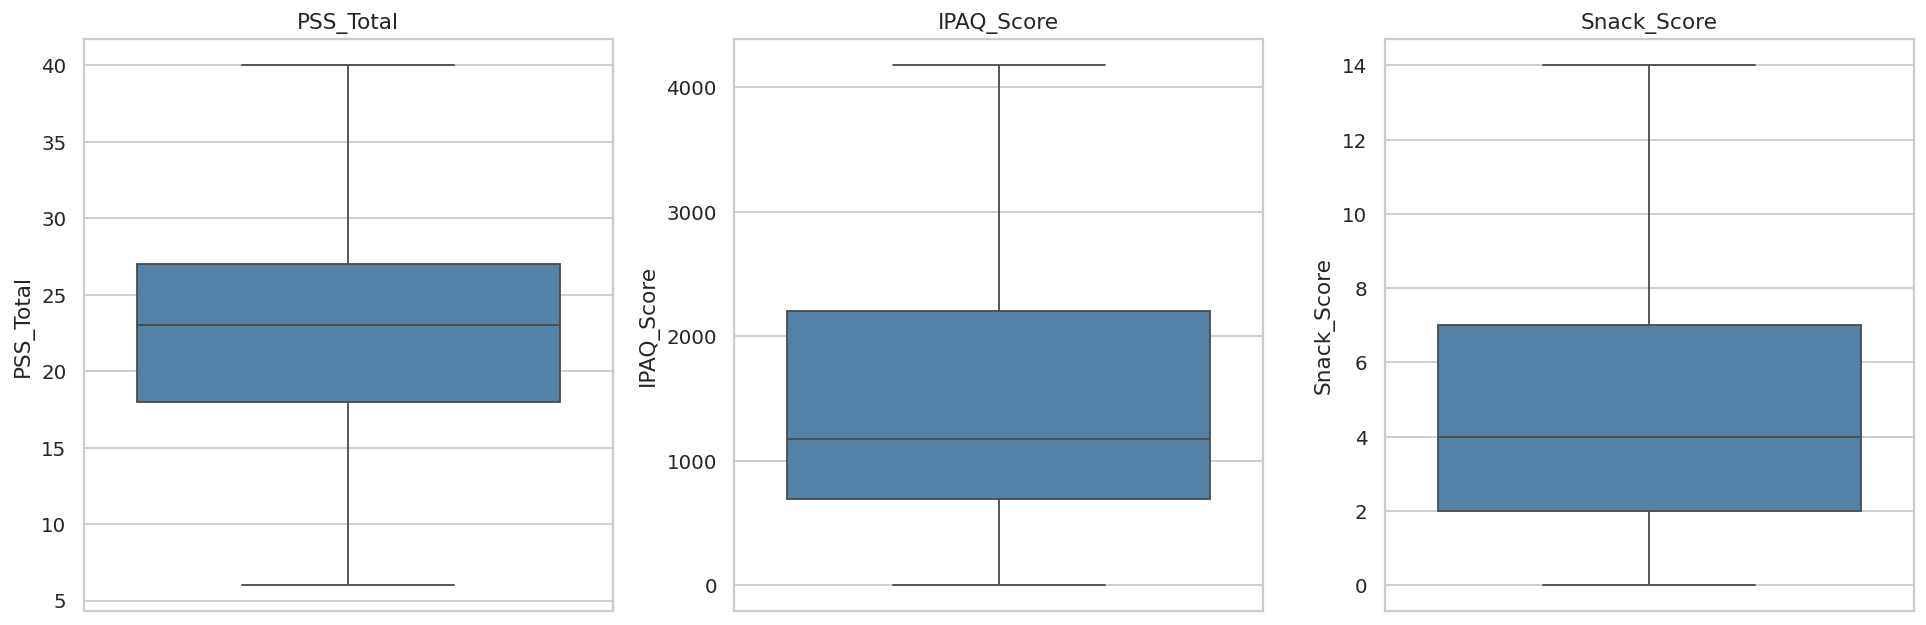

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

features = ["PSS_Total", "IPAQ_Score", "Snack_Score"]

for ax, feature in zip(axes, features):
    sns.boxplot(y=df[feature], ax=ax, color="steelblue", showfliers=False)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

In [8]:
Q1 = df["IPAQ_Score"].quantile(0.25)
Q3 = df["IPAQ_Score"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 3 * IQR

outliers = df[df["IPAQ_Score"] > upper_bound]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))

print("Flagged records are not displayed in the public notebook.")

Q1: 693.0
Q3: 2201.75
IQR: 1508.75
Upper bound: 6728.0
Number of outliers: 3
Flagged records are not displayed in the public notebook.


In [9]:
df_clean = df[
    df["IPAQ_Score"] <= upper_bound
].copy().reset_index(drop=True)

print("Original dataset:", len(df))
print("Removed observations:", len(df) - len(df_clean))
print("Cleaned dataset:", len(df_clean))

Original dataset: 146
Removed observations: 3
Cleaned dataset: 143


## 3. Exploratory data analysis
Cronbach alpha assesses internal consistency, not validity. Examine distributions and Spearman rank correlations; p-values are exploratory and do not imply causation.

In [10]:
pss_clean = df_clean[pss_columns].copy()

pss_clean[reverse_columns] = (
    4 - pss_clean[reverse_columns]
)

k = pss_clean.shape[1]

item_variances = pss_clean.var(ddof=1)

total_variance = pss_clean.sum(axis=1).var(ddof=1)

cronbach_alpha = (
    k / (k - 1)
) * (
    1 - item_variances.sum() / total_variance
)

print(f"Cronbach's Alpha: {cronbach_alpha:.3f}")

Cronbach's Alpha: 0.838


In [11]:
features = [
    "PSS_Total",
    "IPAQ_Score",
    "Snack_Score"
]

df_clean[features].describe().round(2)

,PSS_Total,IPAQ_Score,Snack_Score
count,143.00,143.00,143.00
mean,22.90,1521.77,4.87
std,6.72,1257.36,3.68
min,2.00,0.00,0.00
25%,18.50,693.00,2.00
50%,23.00,1173.00,4.00
75%,27.00,2136.00,7.00
max,40.00,5838.00,21.00


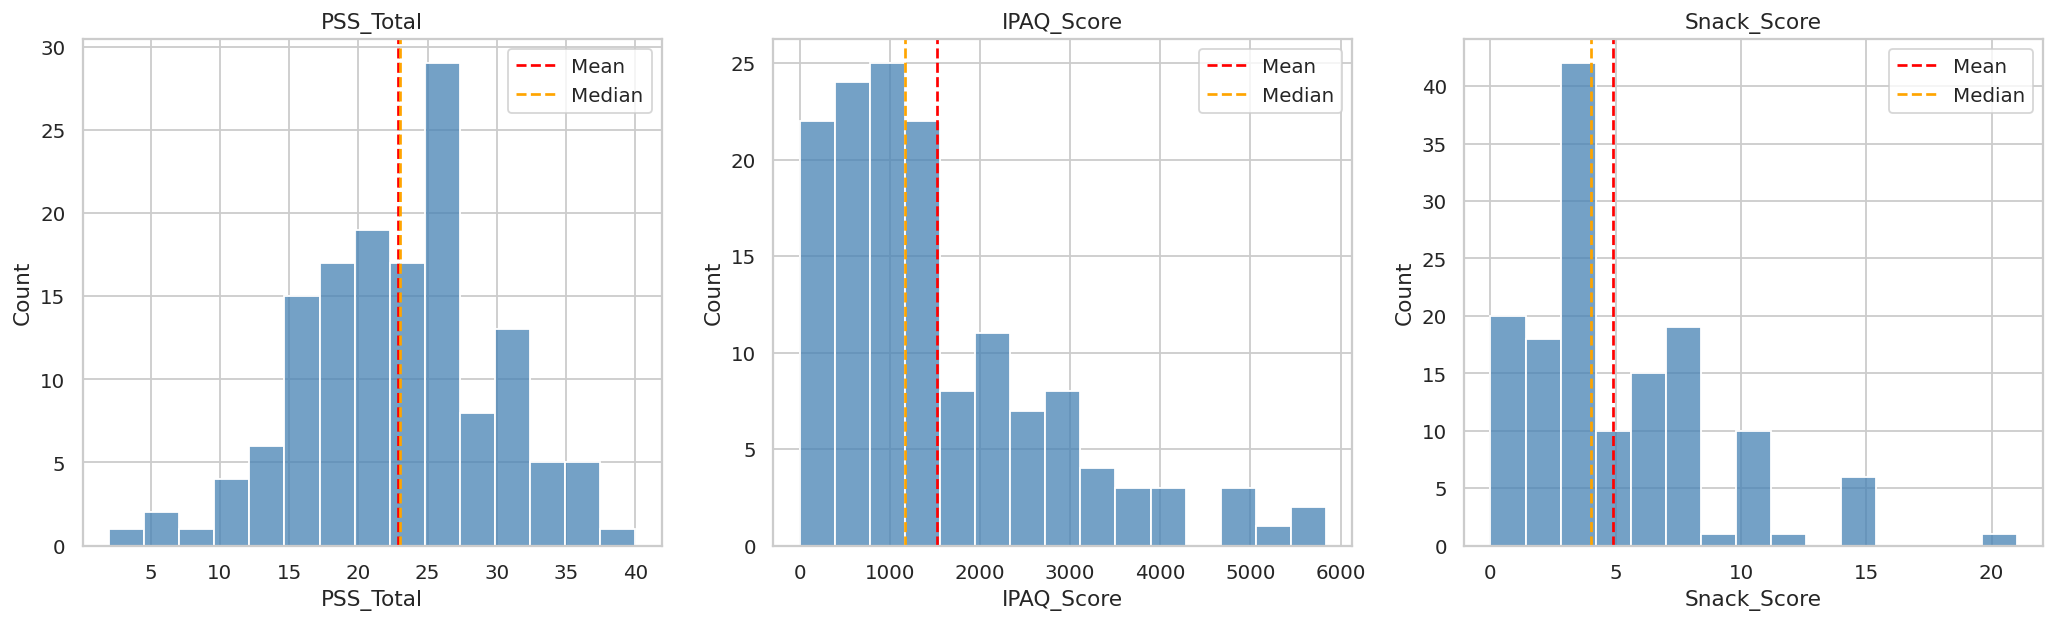

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, features):

    sns.histplot(
        data=df_clean,
        x=feature,
        bins=15,
        color="steelblue",
        ax=ax
    )

    ax.axvline(
        df_clean[feature].mean(),
        color="red",
        linestyle="--",
        label="Mean"
    )

    ax.axvline(
        df_clean[feature].median(),
        color="orange",
        linestyle="--",
        label="Median"
    )

    ax.set_title(feature)
    ax.legend()

plt.tight_layout()
plt.show()

             PSS_Total  IPAQ_Score  Snack_Score
PSS_Total        1.000      -0.295        0.056
IPAQ_Score      -0.295       1.000       -0.062
Snack_Score      0.056      -0.062        1.000


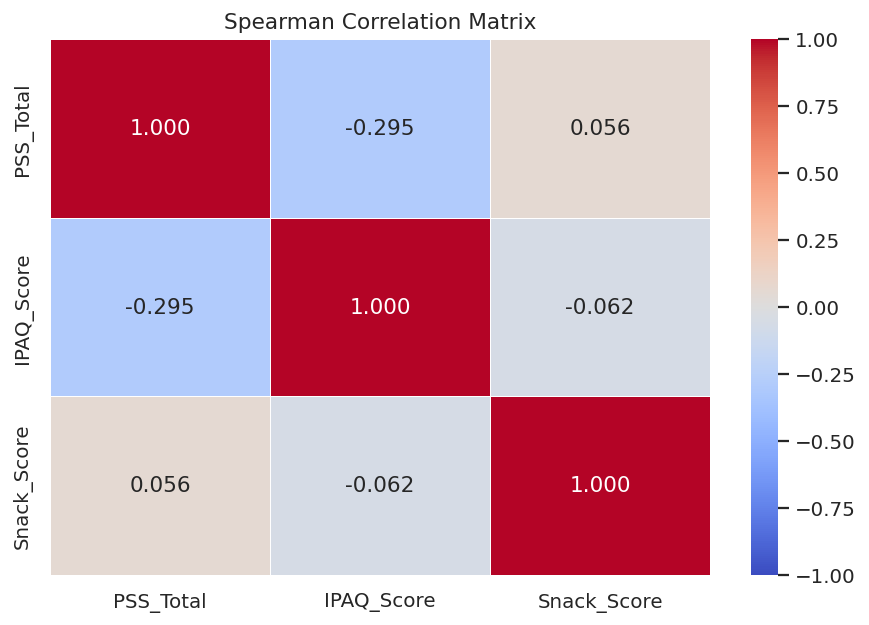

In [13]:
correlation_matrix = df_clean[features].corr(
    method="spearman"
)

print(correlation_matrix.round(3))

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".3f",
    linewidths=0.5
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

In [14]:
from scipy.stats import spearmanr

for i, var1 in enumerate(features):

    for var2 in features[i + 1:]:

        correlation, p_value = spearmanr(
            df_clean[var1],
            df_clean[var2]
        )

        print(f"{var1} vs {var2}")
        print(f"Correlation: {correlation:.3f}")
        print(f"P-value: {p_value:.5f}")
        print("-" * 40)

PSS_Total vs IPAQ_Score
Correlation: -0.295
P-value: 0.00035
----------------------------------------
PSS_Total vs Snack_Score
Correlation: 0.056
P-value: 0.50928
----------------------------------------
IPAQ_Score vs Snack_Score
Correlation: -0.062
P-value: 0.46219
----------------------------------------


## 4. Features and standardization
Model only PSS, IPAQ and snack score. Use sample-standard-deviation z-scores (ddof=1) to match the report; demographics are reserved for profiling.

In [15]:
X = df_clean[
    ["PSS_Total", "IPAQ_Score", "Snack_Score"]
].copy()

print("Model input shape:", X.shape)

X.describe().round(2)

Model input shape: (143, 3)


,PSS_Total,IPAQ_Score,Snack_Score
count,143.00,143.00,143.00
mean,22.90,1521.77,4.87
std,6.72,1257.36,3.68
min,2.00,0.00,0.00
25%,18.50,693.00,2.00
50%,23.00,1173.00,4.00
75%,27.00,2136.00,7.00
max,40.00,5838.00,21.00


In [16]:
X_scaled = (X - X.mean()) / X.std(ddof=1)

print("Standardized matrix shape:", X_scaled.shape)

Standardized matrix shape: (143, 3)


In [17]:
X_scaled.agg(["mean", "std", "min", "max"]).round(4)

,PSS_Total,IPAQ_Score,Snack_Score
mean,-0.0000,-0.0000,-0.0000
std,1.0000,1.0000,1.0000
min,-3.1116,-1.2103,-1.3253
max,2.5472,3.4328,4.3889


## 5. Model selection
Compare WCSS and silhouette over candidate k. Use seed 42 and 50 initializations. The independent k=4 has the highest silhouette (0.3151); k=3 remains an interpretable reference with fewer segments and comparable business questions.

In [18]:
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=50
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

print(wcss)

[425.99999999999994, 298.6578956873222, 221.43461533094725, 173.10304743289998, 147.56686716363916, 127.37849926273216, 112.72324316056006, 98.03058078124147]


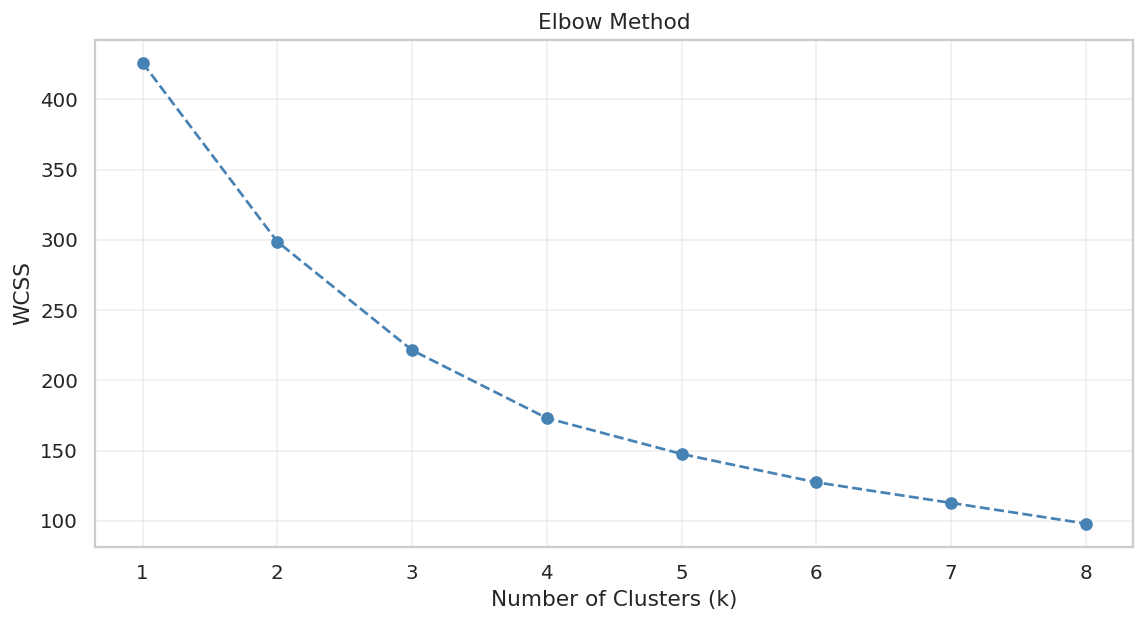

In [19]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, 9),
    wcss,
    marker="o",
    linestyle="--",
    color="steelblue"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.xticks(range(1, 9))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=50
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(f"k={k} | Silhouette Score: {score:.4f}")

k=2 | Silhouette Score: 0.2965
k=3 | Silhouette Score: 0.2980
k=4 | Silhouette Score: 0.3151
k=5 | Silhouette Score: 0.2813
k=6 | Silhouette Score: 0.2995
k=7 | Silhouette Score: 0.2921
k=8 | Silhouette Score: 0.2988


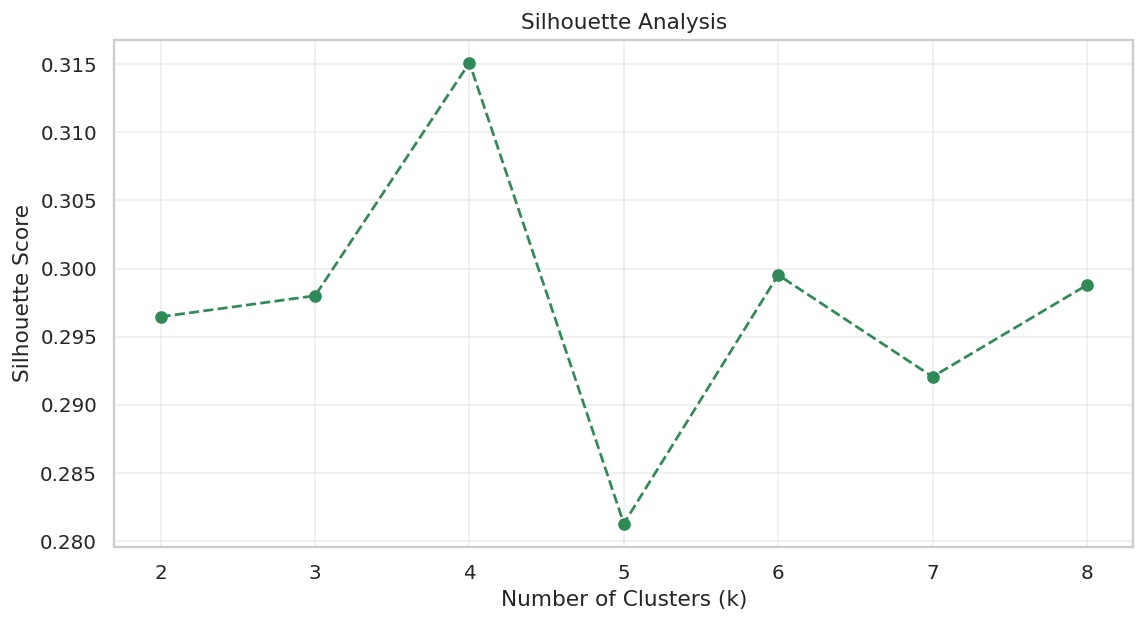

In [21]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 9),
    silhouette_scores,
    marker="o",
    linestyle="--",
    color="seagreen"
)

plt.title("Silhouette Analysis")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Compare three and four clusters
Inspect centers and sizes using common plot limits. A fourth cluster reshuffles membership; it does not simply split one existing group.

In [22]:
model_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=50
)

model_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=50
)

df_clean["Cluster_3"] = model_3.fit_predict(X_scaled)
df_clean["Cluster_4"] = model_4.fit_predict(X_scaled)

print("3-Cluster Model:")
print(df_clean["Cluster_3"].value_counts().sort_index())

print("\n4-Cluster Model:")
print(df_clean["Cluster_4"].value_counts().sort_index())

3-Cluster Model:
Cluster_3
0    68
1    31
2    44
Name: count, dtype: int64

4-Cluster Model:
Cluster_4
0    64
1    42
2    18
3    19
Name: count, dtype: int64


In [23]:
centers_3 = pd.DataFrame(
    model_3.cluster_centers_,
    columns=X_scaled.columns
)

centers_4 = pd.DataFrame(
    model_4.cluster_centers_,
    columns=X_scaled.columns
)

print("3-Cluster Centers:")
print(centers_3.round(3))

print("\n4-Cluster Centers:")
print(centers_4.round(3))

3-Cluster Centers:
   PSS_Total  IPAQ_Score  Snack_Score
0      0.294      -0.572       -0.473
1      0.280      -0.448        1.466
2     -0.651       1.200       -0.302

4-Cluster Centers:
   PSS_Total  IPAQ_Score  Snack_Score
0      0.614      -0.536       -0.271
1     -1.045       0.136       -0.360
2      0.297      -0.479        2.031
3     -0.039       1.958       -0.215


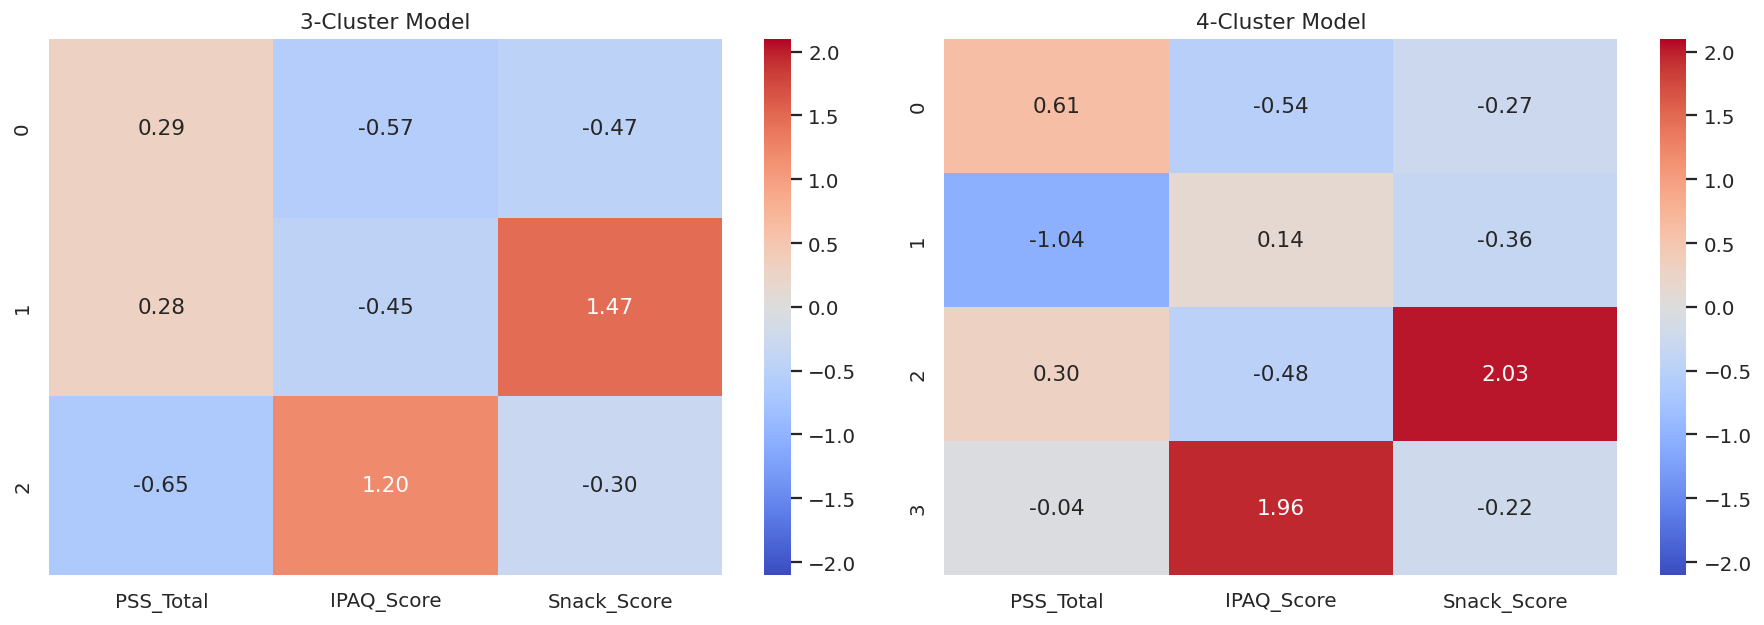

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    centers_3,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-2.1,
    vmax=2.1,
    fmt=".2f",
    ax=axes[0]
)

sns.heatmap(
    centers_4,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-2.1,
    vmax=2.1,
    fmt=".2f",
    ax=axes[1]
)

axes[0].set_title("3-Cluster Model")
axes[1].set_title("4-Cluster Model")

plt.tight_layout()
plt.show()

## 7. Profiles and replication
Use the independent k=3 model as the main new analysis. Compare to original centers separately. Known-center initialization is a reconstruction, not independent confirmation of the optimal model.

In [25]:
transition_table = pd.crosstab(
    df_clean["Cluster_3"],
    df_clean["Cluster_4"],
    rownames=["3-Cluster Model"],
    colnames=["4-Cluster Model"],
    margins=True
)

transition_table

4-Cluster Model,0,1,2,3,All
3-Cluster Model,,,,,
0,54,14,0,0,68
1,9,4,18,0,31
2,1,24,0,19,44
All,64,42,18,19,143


In [26]:
df_clean["Cluster"] = df_clean["Cluster_3"]

cluster_profile = df_clean.groupby("Cluster")[
    features
].mean()

cluster_profile["Count"] = (
    df_clean["Cluster"].value_counts()
)

cluster_profile["Percentage"] = (
    cluster_profile["Count"] / len(df_clean) * 100
)

cluster_profile.round(2)

,PSS_Total,IPAQ_Score,Snack_Score,Count,Percentage
Cluster,,,,,
0,24.87,802.84,3.13,68,47.55
1,24.77,958.03,10.26,31,21.68
2,18.52,3030.05,3.76,44,30.77


In [27]:
spss_centers = np.array([
    [0.29218, -0.54915, -0.34645],
    [-0.65111, 1.19955, -0.30184],
    [0.27961, -0.47708, 1.81625]
])

model_spss = KMeans(
    n_clusters=3,
    init=spss_centers,
    n_init=1,
    random_state=42
)

df_clean["Cluster_SPSS"] = (
    model_spss.fit_predict(X_scaled) + 1
)

print(
    df_clean["Cluster_SPSS"]
    .value_counts()
    .sort_index()
)

Cluster_SPSS
1    77
2    44
3    22
Name: count, dtype: int64


## 8. Agreement and commercial profiling
ARI measures label-invariant agreement, not an accuracy percentage. Examine aggregate budget, age and product preferences; preserve the original category labels. Kruskal–Wallis tests are exploratory.

In [28]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    df_clean["Cluster_SPSS"],
    df_clean["Cluster_3"]
)

print(f"Adjusted Rand Index: {ari:.4f}")

Adjusted Rand Index: 0.8316


In [29]:
demographic_profile = df_clean.groupby("Cluster").agg(
    Customer_Count=("Age", "size"),
    Average_Age=("Age", "mean"),
    Average_Budget=("Budget", "mean"),
    Median_Budget=("Budget", "median")
)

demographic_profile.round(2)

,Customer_Count,Average_Age,Average_Budget,Median_Budget
Cluster,,,,
0,68,22.85,14577.94,12000.0
1,31,21.55,13225.81,10000.0
2,44,22.73,14461.36,8000.0


In [30]:
preference_map = {
    1: "Chocolate & Bars",
    2: "Bakery & Pastry",
    3: "Heavy Desserts (Baklava etc.)",
    4: "Frozen Treats (Ice Cream etc.)",
    5: "I don't Distinguish"
}

df_clean["Product_Preference"] = (
    df_clean["Sweet_Pref"].map(preference_map)
)

preference_table = pd.crosstab(
    df_clean["Cluster"],
    df_clean["Product_Preference"],
    normalize="index"
) * 100

preference_table.round(1)

Product_Preference,Bakery & Pastry,Chocolate & Bars,Frozen Treats (Ice Cream etc.),Heavy Desserts (Baklava etc.),I don't Distinguish
Cluster,,,,,
0,16.2,39.7,2.9,8.8,32.4
1,9.7,48.4,0.0,9.7,32.3
2,11.4,40.9,2.3,6.8,38.6


In [31]:
from scipy.stats import kruskal

test_variables = ["Age", "Budget"]

for variable in test_variables:

    groups = [
        group[variable].values
        for _, group in df_clean.groupby("Cluster")
    ]

    statistic, p_value = kruskal(*groups)

    print(f"{variable}")
    print(f"H-statistic: {statistic:.3f}")
    print(f"P-value: {p_value:.5f}")
    print("-" * 30)

Age
H-statistic: 9.232
P-value: 0.00989
------------------------------
Budget
H-statistic: 2.214
P-value: 0.33060
------------------------------


## 9. Compare original product-preference distributions
The reference-initialized solution reproduces all 15 rounded percentages in the report’s page 60 chart.

In [32]:
original_preferences = pd.crosstab(
    df_clean["Cluster_SPSS"],
    df_clean["Product_Preference"],
    normalize="index"
) * 100

original_preferences = original_preferences.reindex(
    columns=list(preference_map.values())
)

original_preferences.round(1)

Product_Preference,Chocolate & Bars,Bakery & Pastry,Heavy Desserts (Baklava etc.),Frozen Treats (Ice Cream etc.),I don't Distinguish
Cluster_SPSS,,,,,
1,41.6,15.6,10.4,2.6,29.9
2,40.9,11.4,6.8,2.3,38.6
3,45.5,9.1,4.5,0.0,40.9


## 10. PCA visualization
Project the three standardized inputs to two principal components. Only aggregate centers are shown publicly; explained variance is not classification accuracy.

In [33]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled.to_numpy())

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=df_clean.index
)

pca_df["Cluster"] = df_clean["Cluster"].astype(str)  # kept in memory only

explained_variance = pca.explained_variance_ratio_

print("PC1:", round(explained_variance[0] * 100, 2))
print("PC2:", round(explained_variance[1] * 100, 2))

print(
    "Total explained variance:",
    round(explained_variance.sum() * 100, 2)
)

PC1: 44.14
PC2: 31.5
Total explained variance: 75.64


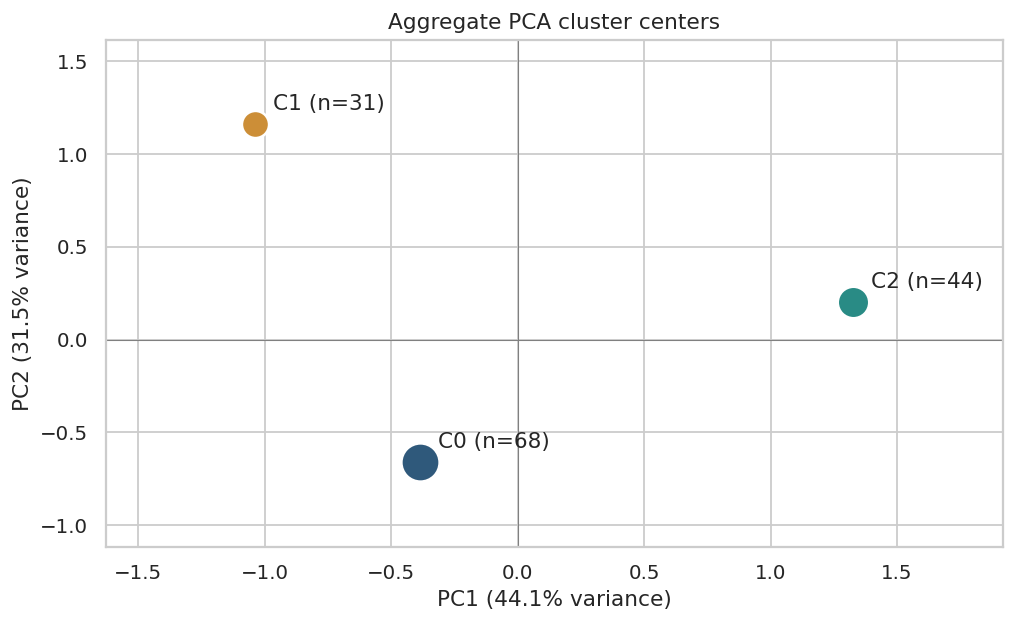

In [34]:
pca_centers = pca.transform(model_3.cluster_centers_)
counts = df_clean["Cluster"].value_counts().sort_index()
colors = ["#2F597B", "#CC8E37", "#298B85"]

fig, ax = plt.subplots(figsize=(8, 5))
for i, (x, y) in enumerate(pca_centers):
    ax.scatter(x, y, s=40 + 6 * counts[i], c=colors[i],
               edgecolor="white", linewidth=1.4)
    ax.annotate(f"C{i} (n={counts[i]})", (x, y),
                xytext=(10, 8), textcoords="offset points")
ax.axhline(0, color="gray", linewidth=.6)
ax.axvline(0, color="gray", linewidth=.6)
ax.set(title="Aggregate PCA cluster centers",
       xlabel=f"PC1 ({explained_variance[0]:.1%} variance)",
       ylabel=f"PC2 ({explained_variance[1]:.1%} variance)")
ax.margins(.25)
fig.tight_layout()
plt.show()

## 11. Commercial summary
Present sample shares and product preference percentages. Product concepts are hypotheses, not observed campaign or sales results.

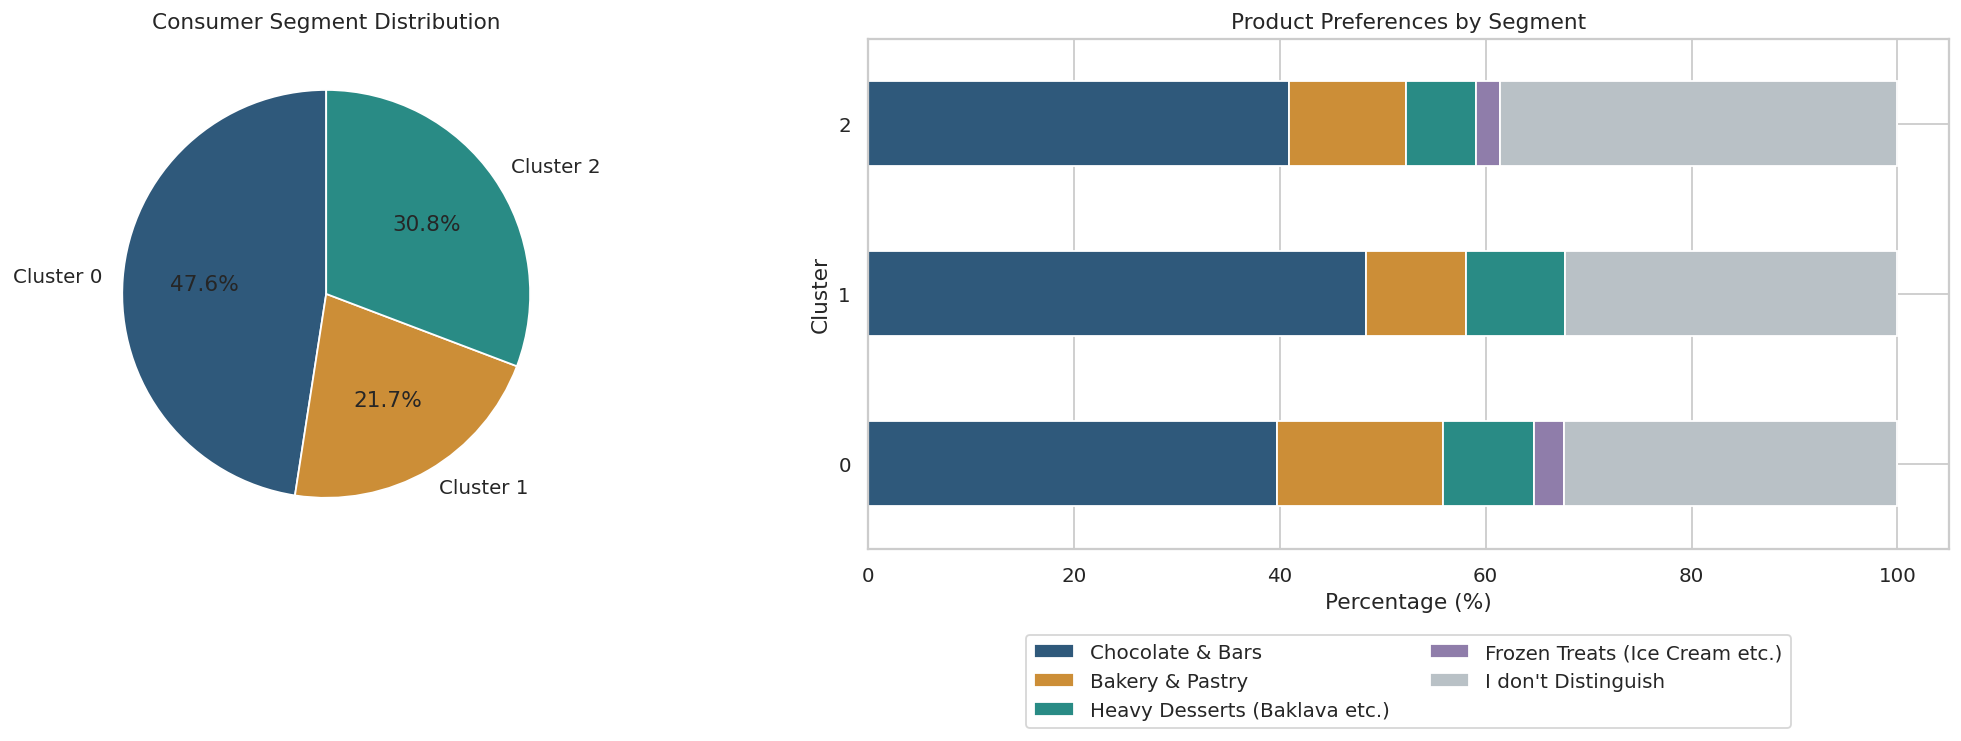

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

cluster_counts = df_clean["Cluster"].value_counts().sort_index()

axes[0].pie(
    cluster_counts,
    labels=[f"Cluster {i}" for i in cluster_counts.index],
    autopct="%1.1f%%",
    colors=colors,
    startangle=90
)

axes[0].set_title("Consumer Segment Distribution")

preference_table = preference_table.reindex(
    columns=list(preference_map.values())
)

preference_table.plot(
    kind="barh",
    stacked=True,
    color=["#2F597B", "#CC8E37", "#298B85", "#8F7DAA", "#B9C1C6"],
    ax=axes[1]
)

axes[1].set_title("Product Preferences by Segment")
axes[1].set_xlabel("Percentage (%)")
axes[1].set_ylabel("Cluster")

axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=2
)

plt.tight_layout()
plt.show()

## 12. Decision and limitations
Independent k=3 remains the primary exploratory model; k=4 is a comparator (silhouette 0.3151 vs 0.2980). Three groups are more parsimonious, all contain at least 31 observations, and match the original research question. My recollection is that the 2025 three-cluster choice combined the elbow curve and the need for distinct marketing ideas. The fourth-cluster removal procedure is not documented.

Chocolate & Bars is the highest reported preference across all three groups, and budget differences were not supported by the exploratory Kruskal–Wallis test. Original team recommendations are retained as inspiration; test transparent pack/assortment formats and convenience concepts, not stress-targeted messages or unsupported nutritional/health claims. No sales uplift has been measured.

Convenience sampling, a small and demographically imbalanced sample, self-reporting, and cross-sectional design limit generalization. See README and the case study for the original-versus-independent mapping and responsible marketing tests. Raw workbook and individual plots are not distributed.
